# 03 – Modelling
**Task:** day-ahead forecasting of power consumption for the 3 zones of Tetouan city
(10-minute resolution, 3 outputs predicted together).

## Model technique selection
| # | Model | Type | Why it is included |
|---|-------|------|--------------------|
| 1 | Naive (yesterday's value) | Baseline | Simplest possible forecast; every model must beat it |
| 2 | Linear Regression | Classical ML | Fast, interpretable linear baseline |
| 3 | Random Forest | Classical ML | Strong non-linear baseline for tabular data |
| 4 | MLP (Dense neural network) | Deep learning | Learns non-linear interactions between features |
| 5 | LSTM | Deep learning (RNN) | Designed for sequences; uses the last 6 hours of features |
| 6 | GRU | Deep learning (RNN) | Lighter alternative to LSTM, often trains faster |

### Only if you use Google Colab
Run the cell below (remove the `#` signs and put your GitHub username). Then run notebook 02 first
in Colab, because `data/processed` is not on GitHub. Also select **Runtime → Change runtime type → GPU**.
If you run on your laptop, skip this cell.

In [1]:
# COLAB ONLY
# !git clone https://github.com/YOUR_USERNAME/tetouan-power-consumption-dl.git
# %cd tetouan-power-consumption-dl/notebooks

In [ ]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_absolute_percentage_error)

import tensorflow as tf
import keras
from keras import layers

keras.utils.set_random_seed(42)      # reproducible results
sns.set_theme(style="whitegrid")

DATA_DIR, MODEL_DIR, RESULTS_DIR, FIG_DIR = "../data/processed", "../models", "../results", "../figures"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


## 0. Make sure the prepared data is up to date
This cell repeats the final data preparation steps from notebook 02 (day-ahead lag features,
monthly block split, scaling) and saves the files again. This way notebook 03 always uses the
correct, latest version of the prepared data, even if notebook 02 was not re-run.

In [3]:
from sklearn.preprocessing import MinMaxScaler
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(MODEL_DIR, exist_ok=True)

raw = pd.read_csv("../data/Tetuan_City_power_consumption.csv")
raw.columns = raw.columns.str.replace(r"\s+", " ", regex=True).str.strip()
raw = raw.rename(columns={"Wind Speed": "WindSpeed", "general diffuse flows": "GeneralDiffuseFlows",
                          "diffuse flows": "DiffuseFlows", "Zone 1 Power Consumption": "Zone1",
                          "Zone 2 Power Consumption": "Zone2", "Zone 3 Power Consumption": "Zone3"})
raw["DateTime"] = pd.to_datetime(raw["DateTime"], format="%m/%d/%Y %H:%M")
raw = raw.set_index("DateTime").sort_index()

WEATHER   = ["Temperature", "Humidity", "WindSpeed", "GeneralDiffuseFlows", "DiffuseFlows"]
TARGETS   = ["Zone1", "Zone2", "Zone3"]
CYCLICAL  = ["time_sin", "time_cos", "dow_sin", "dow_cos", "month_sin", "month_cos", "is_weekend"]
LAG_TYPES = ["lag1d", "lag7d", "mean1d"]

minute_of_day = raw.index.hour * 60 + raw.index.minute
raw["time_sin"]   = np.sin(2 * np.pi * minute_of_day / 1440)
raw["time_cos"]   = np.cos(2 * np.pi * minute_of_day / 1440)
raw["dow_sin"]    = np.sin(2 * np.pi * raw.index.dayofweek / 7)
raw["dow_cos"]    = np.cos(2 * np.pi * raw.index.dayofweek / 7)
raw["month_sin"]  = np.sin(2 * np.pi * (raw.index.month - 1) / 12)
raw["month_cos"]  = np.cos(2 * np.pi * (raw.index.month - 1) / 12)
raw["is_weekend"] = (raw.index.dayofweek >= 5).astype(int)
for z in TARGETS:
    raw[f"{z}_lag1d"]  = raw[z].shift(144)
    raw[f"{z}_lag7d"]  = raw[z].shift(1008)
    raw[f"{z}_mean1d"] = raw[z].shift(144).rolling(144).mean()
raw = raw.dropna()

LAGS = [f"{z}_{t}" for t in LAG_TYPES for z in TARGETS]
FEATURES = WEATHER + CYCLICAL + LAGS

day = raw.index.day
parts = {"train": raw[day <= 20], "val": raw[(day > 20) & (day <= 25)], "test": raw[day > 25]}

feature_scaler = MinMaxScaler().fit(parts["train"][WEATHER + CYCLICAL])
target_scaler  = MinMaxScaler().fit(parts["train"][TARGETS])
for name, part in parts.items():
    out = part[FEATURES + TARGETS].copy()
    out[WEATHER + CYCLICAL] = feature_scaler.transform(part[WEATHER + CYCLICAL])
    out[TARGETS] = target_scaler.transform(part[TARGETS])
    for t in LAG_TYPES:
        cols = [f"{z}_{t}" for z in TARGETS]
        out[cols] = target_scaler.transform(part[cols].set_axis(TARGETS, axis=1))
    out.to_csv(f"{DATA_DIR}/{name}.csv")

joblib.dump(feature_scaler, f"{MODEL_DIR}/feature_scaler.pkl")
joblib.dump(target_scaler,  f"{MODEL_DIR}/target_scaler.pkl")
joblib.dump({"WEATHER": WEATHER, "CYCLICAL": CYCLICAL, "LAGS": LAGS, "LAG_TYPES": LAG_TYPES,
             "TARGETS": TARGETS, "FEATURES": FEATURES}, f"{MODEL_DIR}/feature_config.pkl")
print("Prepared data saved:", {k: len(v) for k, v in parts.items()}, "| features:", len(FEATURES))

C:\Users\olsas\AppData\Local\Temp\ipykernel_11772\3321517665.py:20: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  raw["dow_sin"]    = np.sin(2 * np.pi * raw.index.dayofweek / 7)
C:\Users\olsas\AppData\Local\Temp\ipykernel_11772\3321517665.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  raw["dow_cos"]    = np.cos(2 * np.pi * raw.index.dayofweek / 7)
C:\Users\olsas\AppData\Local\Temp\ipykernel_11772\3321517665.py:24: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  raw["is_weekend"] = (raw.index.dayofweek >= 5).astype(int)


Prepared data saved: {'train': 33552, 'val': 8640, 'test': 9216} | features: 21


## 1. Load prepared data

In [4]:
train = pd.read_csv(f"{DATA_DIR}/train.csv", index_col="DateTime", parse_dates=True)
val   = pd.read_csv(f"{DATA_DIR}/val.csv",   index_col="DateTime", parse_dates=True)
test  = pd.read_csv(f"{DATA_DIR}/test.csv",  index_col="DateTime", parse_dates=True)

cfg = joblib.load(f"{MODEL_DIR}/feature_config.pkl")
target_scaler = joblib.load(f"{MODEL_DIR}/target_scaler.pkl")
FEATURES, TARGETS = cfg["FEATURES"], cfg["TARGETS"]

print("Train:", train.shape, " Val:", val.shape, " Test:", test.shape)
print("Features:", len(FEATURES), " Targets:", TARGETS)

Train: (33552, 24)  Val: (8640, 24)  Test: (9216, 24)
Features: 21  Targets: ['Zone1', 'Zone2', 'Zone3']


## 2. Test design
- **Sequence input for LSTM/GRU:** each sample is a window of the last `WINDOW = 36` time steps
  (6 hours) of all 21 features; the target is the consumption of the 3 zones at the last step.
- Windows are created **inside each monthly block only**, so a window never jumps across the gap
  between train / validation / test days.
- **Fair comparison:** all models are evaluated on exactly the same test rows (the rows that have
  a full 6-hour window).
- **Metrics** (computed in KW, after converting predictions back from the 0–1 scale):
  MAE, RMSE, R² and MAPE, for each zone.
- **Validation set** is used for early stopping of the neural networks; the **test set** is used only once, at the end.

In [5]:
WINDOW = 36   # 36 x 10 min = 6 hours

def make_windows(df_part):
    """Create (samples, WINDOW, features) arrays inside each monthly block."""
    X_list, y_list, idx_list = [], [], []
    for _, block in df_part.groupby(df_part.index.month):
        X = block[FEATURES].values.astype("float32")
        y = block[TARGETS].values.astype("float32")
        Xw = np.lib.stride_tricks.sliding_window_view(X, WINDOW, axis=0).transpose(0, 2, 1)
        X_list.append(Xw)
        y_list.append(y[WINDOW - 1:])            # target = last step of each window
        idx_list.append(block.index[WINDOW - 1:])
    index = idx_list[0].append(idx_list[1:])
    return np.concatenate(X_list), np.concatenate(y_list), index

X_train_seq, y_train_seq, _ = make_windows(train)
X_val_seq,   y_val_seq,   _ = make_windows(val)
X_test_seq,  y_test_seq, eval_index = make_windows(test)

# Tabular data (for Linear Regression, Random Forest, MLP)
X_train_tab, y_train = train[FEATURES].values, train[TARGETS].values
X_val_tab,   y_val   = val[FEATURES].values,   val[TARGETS].values
X_test_tab  = test.loc[eval_index, FEATURES].values
y_test_eval = test.loc[eval_index, TARGETS].values

print("Sequence shapes  :", X_train_seq.shape, X_val_seq.shape, X_test_seq.shape)
print("Tabular shapes   :", X_train_tab.shape, X_val_tab.shape, X_test_tab.shape)
print("Evaluation rows  :", len(eval_index))

Sequence shapes  : (33132, 36, 21) (8220, 36, 21) (8796, 36, 21)
Tabular shapes   : (33552, 21) (8640, 21) (8796, 21)
Evaluation rows  : 8796


In [6]:
results, predictions, train_times = [], {}, {}

def evaluate(name, y_pred_scaled):
    """Convert predictions back to KW and compute metrics for every zone."""
    y_true = target_scaler.inverse_transform(y_test_eval)
    y_pred = target_scaler.inverse_transform(y_pred_scaled)
    predictions[name] = y_pred
    for i, z in enumerate(TARGETS):
        results.append({
            "Model": name, "Zone": z,
            "MAE":  mean_absolute_error(y_true[:, i], y_pred[:, i]),
            "RMSE": np.sqrt(mean_squared_error(y_true[:, i], y_pred[:, i])),
            "R2":   r2_score(y_true[:, i], y_pred[:, i]),
            "MAPE (%)": mean_absolute_percentage_error(y_true[:, i], y_pred[:, i]) * 100,
        })
    return pd.DataFrame(results).query("Model == @name").round(3)

## 3. Model building
### 3.1 Naive baseline – "tomorrow will be like today"

In [7]:
naive_cols = [f"{z}_lag1d" for z in TARGETS]
train_times["Naive"] = 0.0
evaluate("Naive", test.loc[eval_index, naive_cols].values)

,Model,Zone,MAE,RMSE,R2,MAPE (%)
0,Naive,Zone1,1381.123,2120.230,0.909,4.437
1,Naive,Zone2,1324.562,1872.532,0.876,6.613
2,Naive,Zone3,816.083,1276.433,0.965,4.931


### 3.2 Linear Regression

In [8]:
t = time.time()
lr = LinearRegression().fit(X_train_tab, y_train)
train_times["LinearRegression"] = time.time() - t

joblib.dump(lr, f"{MODEL_DIR}/linear_regression.pkl")
evaluate("LinearRegression", lr.predict(X_test_tab))

,Model,Zone,MAE,RMSE,R2,MAPE (%)
3,LinearRegression,Zone1,1338.617,2043.701,0.916,4.296
4,LinearRegression,Zone2,1123.075,1560.891,0.914,5.423
5,LinearRegression,Zone3,852.859,1261.203,0.965,5.195


### 3.3 Random Forest
`max_depth=12` and `min_samples_leaf=10` limit tree size: accuracy is practically the same as with
deeper trees, but the saved model is ~9 MB instead of ~70 MB.

In [9]:
t = time.time()
rf = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=10,
                           n_jobs=-1, random_state=42).fit(X_train_tab, y_train)
train_times["RandomForest"] = time.time() - t

joblib.dump(rf, f"{MODEL_DIR}/random_forest.pkl", compress=3)
print(f"Training time: {train_times['RandomForest']:.1f} s")
evaluate("RandomForest", rf.predict(X_test_tab))

Training time: 4.3 s


,Model,Zone,MAE,RMSE,R2,MAPE (%)
6,RandomForest,Zone1,1341.512,1964.990,0.922,4.262
7,RandomForest,Zone2,1290.148,1841.913,0.880,6.071
8,RandomForest,Zone3,945.526,1415.956,0.956,5.643


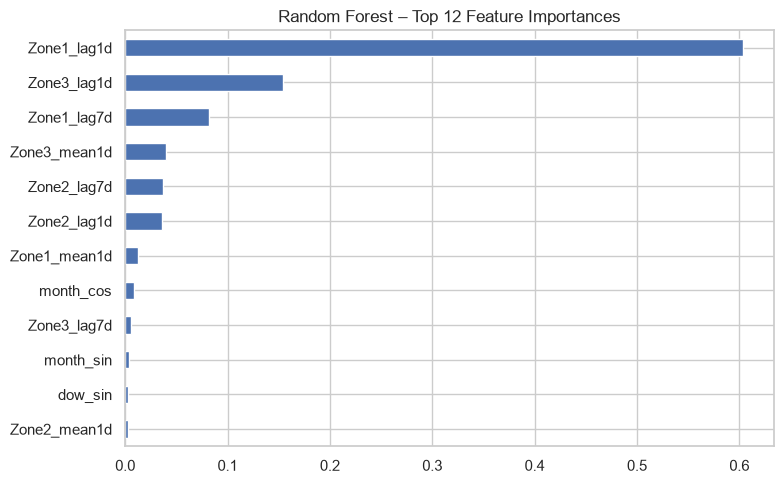

In [10]:
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
importance.tail(12).plot(kind="barh", figsize=(8, 5), title="Random Forest – Top 12 Feature Importances")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/13_rf_feature_importance.png", dpi=150); plt.show()

### Shared settings for the neural networks
- **Loss:** MSE, **optimizer:** Adam (learning rate 0.001), **batch size:** 256, up to 100 epochs
- **EarlyStopping:** stops when validation loss has not improved for 10 epochs and restores the best weights (prevents overfitting)
- **ReduceLROnPlateau:** halves the learning rate when validation loss stops improving
- **Dropout (0.2):** regularisation against overfitting

In [11]:
EPOCHS, BATCH_SIZE = 100, 256
histories = {}

def get_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
    ]

def train_keras(model, X_tr, y_tr, X_v, y_v):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
    t = time.time()
    history = model.fit(X_tr, y_tr, validation_data=(X_v, y_v), epochs=EPOCHS,
                        batch_size=BATCH_SIZE, callbacks=get_callbacks(), verbose=2)
    train_times[model.name] = time.time() - t
    histories[model.name] = history.history
    print(f"{model.name}: {len(history.history['loss'])} epochs, {train_times[model.name]:.0f} s")
    return model

### 3.4 MLP (Multi-Layer Perceptron)

In [12]:
mlp = keras.Sequential([
    layers.Input(shape=(len(FEATURES),)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(len(TARGETS)),
], name="MLP")
mlp.summary()

mlp = train_keras(mlp, X_train_tab, y_train, X_val_tab, y_val)
mlp.save(f"{MODEL_DIR}/mlp.keras")
evaluate("MLP", mlp.predict(X_test_tab, verbose=0))

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,267 (44.01 KB)

 Trainable params: 11,267 (44.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
132/132 - 1s - 11ms/step - loss: 0.0383 - mae: 0.1371 - val_loss: 0.0039 - val_mae: 0.0467 - learning_rate: 0.0010
Epoch 2/100
132/132 - 0s - 3ms/step - loss: 0.0105 - mae: 0.0784 - val_loss: 0.0026 - val_mae: 0.0382 - learning_rate: 0.0010
Epoch 3/100
132/132 - 0s - 3ms/step - loss: 0.0082 - mae: 0.0685 - val_loss: 0.0029 - val_mae: 0.0396 - learning_rate: 0.0010
Epoch 4/100
132/132 - 0s - 3ms/step - loss: 0.0069 - mae: 0.0627 - val_loss: 0.0020 - val_mae: 0.0334 - learning_rate: 0.0010
Epoch 5/100
132/132 - 0s - 3ms/step - loss: 0.0060 - mae: 0.0580 - val_loss: 0.0018 - val_mae: 0.0315 - learning_rate: 0.0010
Epoch 6/100
132/132 - 1s - 4ms/step - loss: 0.0052 - mae: 0.0539 - val_loss: 0.0019 - val_mae: 0.0323 - learning_rate: 0.0010
Epoch 7/100
132/132 - 1s - 4ms/step - loss: 0.0046 - mae: 0.0508 - val_loss: 0.0018 - val_mae: 0.0309 - learning_rate: 0.0010
Epoch 8/100
132/132 - 0s - 3ms/step - loss: 0.0042 - mae: 0.0484 - val_loss: 0.0017 - val_mae: 0.0300 - learning_rate

,Model,Zone,MAE,RMSE,R2,MAPE (%)
9,MLP,Zone1,1346.285,1957.898,0.923,4.329
10,MLP,Zone2,1078.636,1522.350,0.918,5.179
11,MLP,Zone3,1193.166,1562.426,0.947,7.763


### 3.5 LSTM (Long Short-Term Memory)

In [13]:
lstm = keras.Sequential([
    layers.Input(shape=(WINDOW, len(FEATURES))),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(len(TARGETS)),
], name="LSTM")
lstm.summary()

lstm = train_keras(lstm, X_train_seq, y_train_seq, X_val_seq, y_val_seq)
lstm.save(f"{MODEL_DIR}/lstm.keras")
evaluate("LSTM", lstm.predict(X_test_seq, verbose=0))

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 36, 64)         │        22,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 36, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,587 (139.01 KB)

 Trainable params: 35,587 (139.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
130/130 - 10s - 81ms/step - loss: 0.0231 - mae: 0.1070 - val_loss: 0.0050 - val_mae: 0.0549 - learning_rate: 0.0010
Epoch 2/100
130/130 - 8s - 61ms/step - loss: 0.0064 - mae: 0.0611 - val_loss: 0.0029 - val_mae: 0.0402 - learning_rate: 0.0010
Epoch 3/100
130/130 - 8s - 64ms/step - loss: 0.0046 - mae: 0.0510 - val_loss: 0.0026 - val_mae: 0.0373 - learning_rate: 0.0010
Epoch 4/100
130/130 - 11s - 88ms/step - loss: 0.0037 - mae: 0.0458 - val_loss: 0.0022 - val_mae: 0.0341 - learning_rate: 0.0010
Epoch 5/100
130/130 - 9s - 67ms/step - loss: 0.0032 - mae: 0.0422 - val_loss: 0.0019 - val_mae: 0.0318 - learning_rate: 0.0010
Epoch 6/100
130/130 - 9s - 66ms/step - loss: 0.0028 - mae: 0.0396 - val_loss: 0.0018 - val_mae: 0.0305 - learning_rate: 0.0010
Epoch 7/100
130/130 - 8s - 65ms/step - loss: 0.0025 - mae: 0.0374 - val_loss: 0.0016 - val_mae: 0.0292 - learning_rate: 0.0010
Epoch 8/100
130/130 - 9s - 67ms/step - loss: 0.0023 - mae: 0.0361 - val_loss: 0.0016 - val_mae: 0.0284 - lear

,Model,Zone,MAE,RMSE,R2,MAPE (%)
12,LSTM,Zone1,1294.615,1986.099,0.920,4.146
13,LSTM,Zone2,1156.626,1564.163,0.913,5.522
14,LSTM,Zone3,948.897,1336.650,0.961,5.838


### 3.6 GRU (Gated Recurrent Unit)

In [14]:
gru = keras.Sequential([
    layers.Input(shape=(WINDOW, len(FEATURES))),
    layers.GRU(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.GRU(32),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(len(TARGETS)),
], name="GRU")
gru.summary()

gru = train_keras(gru, X_train_seq, y_train_seq, X_val_seq, y_val_seq)
gru.save(f"{MODEL_DIR}/gru.keras")
evaluate("GRU", gru.predict(X_test_seq, verbose=0))

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 36, 64)         │        16,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 36, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,267 (106.51 KB)

 Trainable params: 27,267 (106.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
130/130 - 12s - 93ms/step - loss: 0.0249 - mae: 0.1108 - val_loss: 0.0044 - val_mae: 0.0496 - learning_rate: 0.0010
Epoch 2/100
130/130 - 9s - 72ms/step - loss: 0.0064 - mae: 0.0614 - val_loss: 0.0029 - val_mae: 0.0391 - learning_rate: 0.0010
Epoch 3/100
130/130 - 9s - 66ms/step - loss: 0.0046 - mae: 0.0518 - val_loss: 0.0028 - val_mae: 0.0381 - learning_rate: 0.0010
Epoch 4/100
130/130 - 9s - 66ms/step - loss: 0.0037 - mae: 0.0458 - val_loss: 0.0029 - val_mae: 0.0399 - learning_rate: 0.0010
Epoch 5/100
130/130 - 9s - 67ms/step - loss: 0.0032 - mae: 0.0424 - val_loss: 0.0029 - val_mae: 0.0397 - learning_rate: 0.0010
Epoch 6/100
130/130 - 9s - 67ms/step - loss: 0.0029 - mae: 0.0402 - val_loss: 0.0025 - val_mae: 0.0363 - learning_rate: 0.0010
Epoch 7/100
130/130 - 9s - 69ms/step - loss: 0.0027 - mae: 0.0388 - val_loss: 0.0023 - val_mae: 0.0347 - learning_rate: 0.0010
Epoch 8/100
130/130 - 9s - 67ms/step - loss: 0.0025 - mae: 0.0372 - val_loss: 0.0025 - val_mae: 0.0364 - learn

,Model,Zone,MAE,RMSE,R2,MAPE (%)
15,GRU,Zone1,1554.106,2118.629,0.909,4.847
16,GRU,Zone2,1314.902,1716.984,0.895,6.041
17,GRU,Zone3,1059.878,1420.115,0.956,6.192


## 4. Training curves (overfitting check)

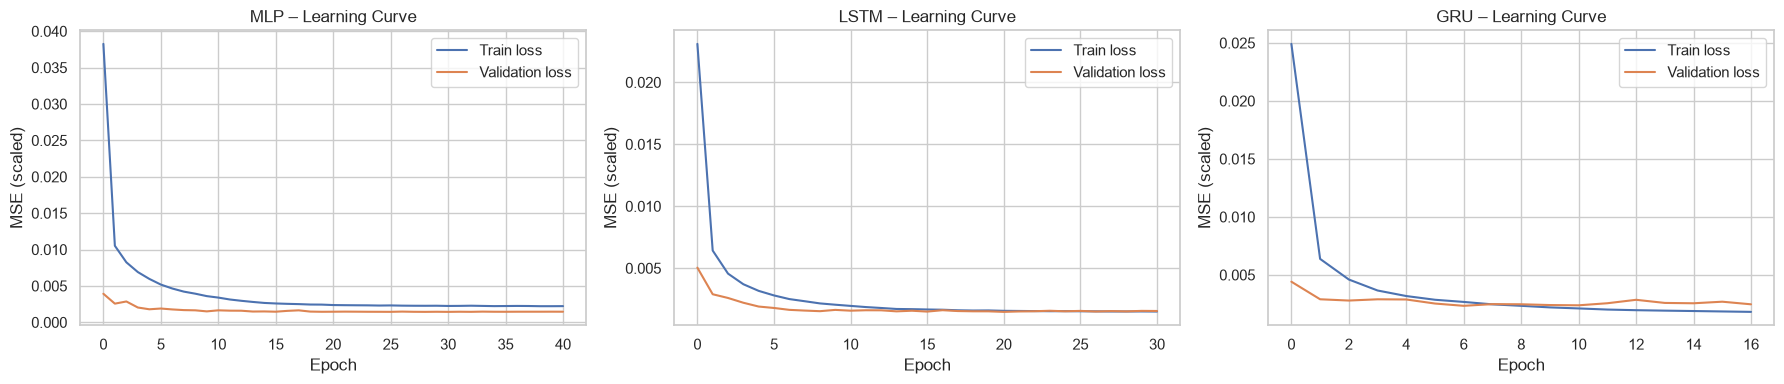

In [15]:
fig, axes = plt.subplots(1, len(histories), figsize=(6 * len(histories), 4))
for ax, (name, h) in zip(np.atleast_1d(axes), histories.items()):
    ax.plot(h["loss"], label="Train loss")
    ax.plot(h["val_loss"], label="Validation loss")
    ax.set_title(f"{name} – Learning Curve")
    ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (scaled)")
    ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/14_learning_curves.png", dpi=150); plt.show()

## 5. Model assessment – comparison of all models

In [16]:
results_df = pd.DataFrame(results)
results_df.to_csv(f"{RESULTS_DIR}/model_results.csv", index=False)

summary = (results_df.groupby("Model", sort=False)[["MAE", "RMSE", "R2", "MAPE (%)"]].mean()
           .assign(**{"Train time (s)": pd.Series(train_times)})
           .sort_values("RMSE").round(3))
summary.to_csv(f"{RESULTS_DIR}/model_summary.csv")
print("Average over the 3 zones (sorted by RMSE):")
summary

Average over the 3 zones (sorted by RMSE):


,MAE,RMSE,R2,MAPE (%),Train time (s)
Model,,,,,
LinearRegression,1104.850,1621.932,0.932,4.971,0.035
LSTM,1133.380,1628.971,0.932,5.169,274.017
MLP,1206.029,1680.891,0.929,5.757,19.293
RandomForest,1192.395,1740.953,0.919,5.326,4.252
GRU,1309.629,1751.909,0.920,5.693,152.850
Naive,1173.923,1756.398,0.916,5.327,0.000


In [17]:
results_df.pivot(index="Model", columns="Zone", values="RMSE").loc[summary.index].round(1)

Zone,Zone1,Zone2,Zone3
Model,,,
LinearRegression,2043.7,1560.9,1261.2
LSTM,1986.1,1564.2,1336.6
MLP,1957.9,1522.3,1562.4
RandomForest,1965.0,1841.9,1416.0
GRU,2118.6,1717.0,1420.1
Naive,2120.2,1872.5,1276.4


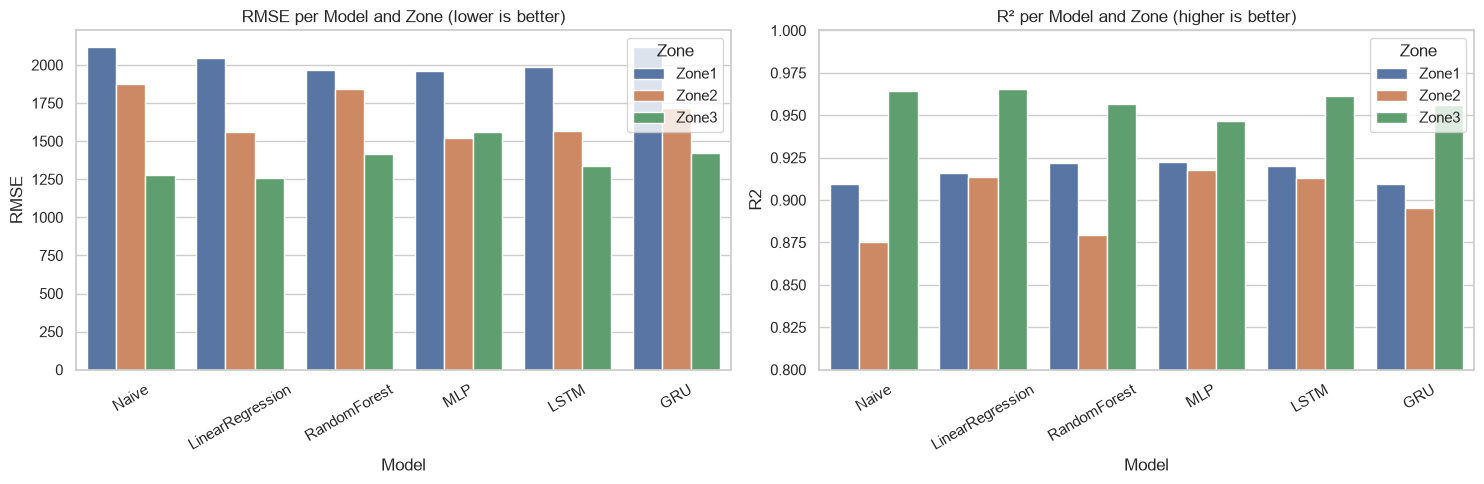

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=results_df, x="Model", y="RMSE", hue="Zone", ax=axes[0])
axes[0].set_title("RMSE per Model and Zone (lower is better)")
sns.barplot(data=results_df, x="Model", y="R2", hue="Zone", ax=axes[1])
axes[1].set_title("R² per Model and Zone (higher is better)")
axes[1].set_ylim(0.8, 1.0)
for ax in axes: ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/15_model_comparison.png", dpi=150); plt.show()

### Save predictions for the Evaluation notebook

In [19]:
np.savez(f"{RESULTS_DIR}/predictions.npz",
         index=np.array(eval_index.strftime("%Y-%m-%d %H:%M"), dtype="U16"),
         y_true=target_scaler.inverse_transform(y_test_eval),
         **predictions)
joblib.dump(histories, f"{RESULTS_DIR}/histories.pkl")
print("Saved:", os.listdir(RESULTS_DIR))
print("Saved models:", os.listdir(MODEL_DIR))

Saved: ['histories.pkl', 'model_results.csv', 'model_summary.csv', 'predictions.npz']
Saved models: ['feature_config.pkl', 'feature_scaler.pkl', 'gru.keras', 'linear_regression.pkl', 'lstm.keras', 'mlp.keras', 'random_forest.pkl', 'target_scaler.pkl']
